### waveform feature table

Allen optotagging tutorial confirms:
-Pvalb neurons predominantly exhibit fast-spiking waveforms
-Pvalb median waveform duration: 0.426 ms → consistent with Allen's
-Our Pvalb candidates include both narrow- and broad-waveform populations which Allen also observes in optotag tutorial
-SST neurons exhibit heterogeneous waveform shapes
-Allen observes a mixture of fast-spiking and regular-spiking waveforms.
-SST candidate median waveform duration: 0.604 ms → longer than Pvalb, consistent with the expected greater prevalence of broader waveforms.
VIP neurons are particularly difficult to identify through optotagging
-Allen reports relatively few clearly light-responsive VIP units.
-VIP candidate median waveform duration: 0.632 ms, with substantial overlap with SST candidates.
-Our pipeline identifies 247 VIP candidates across 8 sessions → requires further validation against Allen's reported low optotagging yield.

Overall: waveform observations are qualitatively consistent with Allen's Pvalb and SST findings, but quantitative correspondence not established yet


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd

from allensdk.brain_observatory.ecephys.ecephys_project_cache import (
    EcephysProjectCache
)

base_dir = Path("/Volumes/WD_BLACK/Spikes2Slope")
cache_dir = base_dir / "allen_visual_coding_data"
results_dir = base_dir / "opto_results"

cache = EcephysProjectCache.from_warehouse(
    manifest=str(cache_dir / "manifest.json")
)

units = cache.get_units().rename_axis("unit_id").reset_index()
opto = pd.read_csv(results_dir / "all_opto_unit_results.csv")

print("Allen QC units:", len(units))
print("Optotagging results:", len(opto))
print("QC-matched tagged candidates:", opto["matched_candidate"].sum())

/Users/keanuventura/miniforge3/envs/allen_env/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Allen QC units: 40010
Optotagging results: 8579
QC-matched tagged candidates: 1127


### master table

In [2]:
waveform_features = [
    "waveform_duration",
    "waveform_halfwidth",
    "waveform_PT_ratio",
    "waveform_repolarization_slope",
    "waveform_recovery_slope",
    "waveform_amplitude",
    "waveform_spread",
    "firing_rate"
]

available = [c for c in waveform_features if c in units.columns]
print("Available features:", available)

unit_columns = [
    "unit_id",
    "ecephys_session_id",
    "ecephys_probe_id",
    "ecephys_structure_acronym",
    "snr",
    "presence_ratio",
    "isi_violations",
    "amplitude_cutoff"
] + available

opto_columns = [
    "unit_id",
    "cre_line",
    "baseline_rate_hz",
    "evoked_rate_hz",
    "response_ratio",
    "candidate_tagged",
    "matched_candidate"
]

master = units[unit_columns].merge(
    opto[opto_columns],
    on="unit_id",
    how="left",
    validate="one_to_one"
)

master["is_opto_candidate"] = (
    master["matched_candidate"].fillna(False).astype(bool)
)

master["cell_type_label"] = np.where(
    master["is_opto_candidate"],
    master["cre_line"],
    "unknown"
)

print("Total units:", len(master))
print(master["cell_type_label"].value_counts())

display(master.head())

Available features: ['waveform_duration', 'waveform_halfwidth', 'waveform_PT_ratio', 'waveform_repolarization_slope', 'waveform_recovery_slope', 'waveform_amplitude', 'waveform_spread', 'firing_rate']
Total units: 40010
unknown    38883
Sst          535
Pvalb        345
Vip          247
Name: cell_type_label, dtype: int64


,unit_id,ecephys_session_id,ecephys_probe_id,ecephys_structure_acronym,snr,presence_ratio,isi_violations,amplitude_cutoff,waveform_duration,waveform_halfwidth,...,waveform_spread,firing_rate,cre_line,baseline_rate_hz,evoked_rate_hz,response_ratio,candidate_tagged,matched_candidate,is_opto_candidate,cell_type_label
0,915956282,732592105,733744647,grey,1.911839,0.99,0.104910,0.072728,0.535678,0.164824,...,30.0,6.519432,NaN,NaN,NaN,NaN,NaN,NaN,False,unknown
1,915956340,732592105,733744647,grey,3.357908,0.99,0.006825,0.000881,0.563149,0.206030,...,30.0,9.660554,NaN,NaN,NaN,NaN,NaN,NaN,False,unknown
2,915956345,732592105,733744647,grey,3.362198,0.99,0.044936,0.001703,0.521943,0.192295,...,30.0,12.698430,NaN,NaN,NaN,NaN,NaN,NaN,False,unknown
3,915956349,732592105,733744647,grey,2.684636,0.99,0.120715,0.096378,0.508208,0.192295,...,40.0,16.192413,NaN,NaN,NaN,NaN,NaN,NaN,False,unknown
4,915956356,732592105,733744647,grey,2.605408,0.99,0.430427,0.054706,0.549414,0.233501,...,60.0,2.193113,NaN,NaN,NaN,NaN,NaN,NaN,False,unknown


In [3]:
output_path = results_dir / "master_waveform_features.csv"

assert master["unit_id"].is_unique
assert len(master) == len(units)

master.to_csv(output_path, index=False)

tagged = master[master["is_opto_candidate"]].copy()

print("Saved to:", output_path)
print("\nLabeled units by interneuron class:")
print(tagged["cell_type_label"].value_counts())

print("\nMissing waveform features:")
display(tagged[available].isna().sum())

display(
    tagged.groupby("cell_type_label")[available]
    .median()
    .round(3)
)

Saved to: /Volumes/WD_BLACK/Spikes2Slope/opto_results/master_waveform_features.csv

Labeled units by interneuron class:
Sst      535
Pvalb    345
Vip      247
Name: cell_type_label, dtype: int64

Missing waveform features:


waveform_duration                 0
waveform_halfwidth               16
waveform_PT_ratio                 0
waveform_repolarization_slope     0
waveform_recovery_slope          16
waveform_amplitude                0
waveform_spread                   0
firing_rate                       0
dtype: int64

,waveform_duration,waveform_halfwidth,waveform_PT_ratio,waveform_repolarization_slope,waveform_recovery_slope,waveform_amplitude,waveform_spread,firing_rate
cell_type_label,,,,,,,,
Pvalb,0.426,0.179,0.511,0.374,-0.068,113.390,80.0,7.087
Sst,0.604,0.206,0.485,0.340,-0.056,115.310,70.0,4.445
Vip,0.632,0.192,0.466,0.405,-0.058,136.897,70.0,3.654


In [9]:
print("Candidates by putative class:")
display(tagged["cell_type_label"].value_counts())

print("\nCandidates and recording groups by class:")
class_coverage = (
    tagged.groupby("cell_type_label")
    .agg(
        n_units=("unit_id", "nunique"),
        n_sessions=("ecephys_session_id", "nunique"),
    )
)
display(class_coverage)

print("\nCandidate counts by session and class:")
session_counts = (
    tagged.groupby(["ecephys_session_id", "cell_type_label"])
    .size()
    .unstack(fill_value=0)
)
display(session_counts)

print("\nMissing feature values:")
display(tagged[available].isna().sum())


Candidates by putative class:


Sst      535
Pvalb    345
Vip      247
Name: cell_type_label, dtype: int64


Candidates and recording groups by class:


,n_units,n_sessions
cell_type_label,,
Pvalb,345,8
Sst,535,12
Vip,247,8



Candidate counts by session and class:


cell_type_label,Pvalb,Sst,Vip
ecephys_session_id,,,
715093703,0,55,0
719161530,0,41,0
721123822,22,0,0
746083955,32,0,0
751348571,0,0,44
755434585,0,0,58
756029989,0,66,0
758798717,0,32,0
760345702,49,0,0



Missing feature values:


waveform_duration                 0
waveform_halfwidth               16
waveform_PT_ratio                 0
waveform_repolarization_slope     0
waveform_recovery_slope          16
waveform_amplitude                0
waveform_spread                   0
firing_rate                       0
dtype: int64

### visualize waveforms

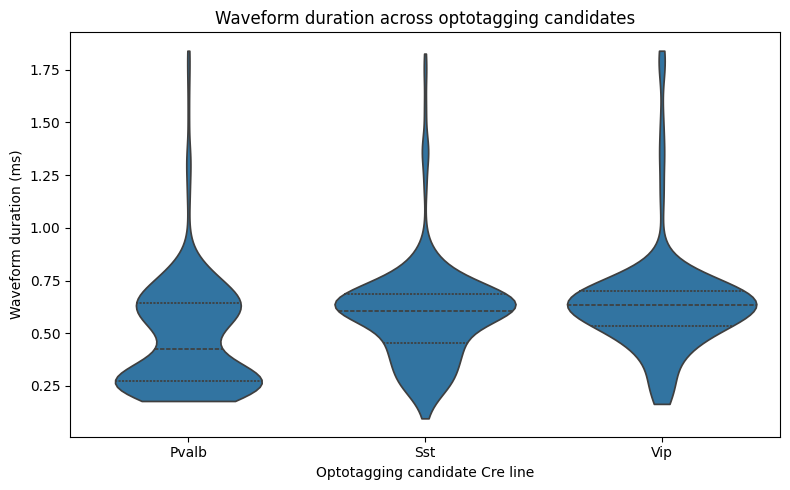

In [10]:

import matplotlib.pyplot as plt
import seaborn as sns

order = ["Pvalb", "Sst", "Vip"]

fig, ax = plt.subplots(figsize=(8, 5))

sns.violinplot(
    data=tagged,
    x="cell_type_label",
    y="waveform_duration",
    order=order,
    inner="quartile",
    cut=0,
    ax=ax
)

ax.set(
    xlabel="Optotagging candidate Cre line",
    ylabel="Waveform duration (ms)",
    title="Waveform duration across optotagging candidates"
)

plt.tight_layout()
plt.show()
